<a href="https://colab.research.google.com/github/Sanika515/AIML/blob/main/6_Facial_Emotion_Recognition_using_CNN_Build_a_convolutional_neural_network_(CNN)_model_to_detect_emotions_from_facial_images_(happy%2C_sad%2C_angry%2C_etc_)_%5BDataset_CK%2B_dataset_%5D_.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!pip -q install kagglehub
import kagglehub
path = kagglehub.dataset_download('shawon10/ckplus')
print(path)

Using Colab cache for faster access to the 'ckplus' dataset.
/kaggle/input/ckplus


Class folders: ['anger', 'contempt', 'disgust', 'fear', 'happy', 'sadness', 'surprise']
Found 981 files belonging to 7 classes.
Using 785 files for training.
Found 981 files belonging to 7 classes.
Using 196 files for validation.
['anger', 'contempt', 'disgust', 'fear', 'happy', 'sadness', 'surprise']


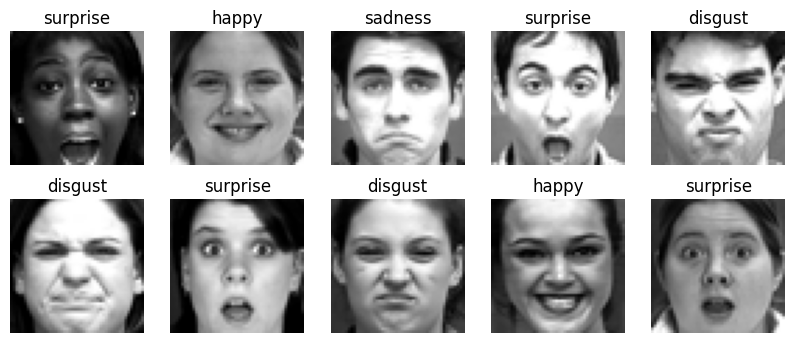

In [ ]:
import os, glob
IMG_EXT = ('.png', '.jpg', '.jpeg', '.bmp')

def find_class_root(p):
    """Return the folder that directly contains the class sub-folders (each holding images)."""
    for root, dirs, files in os.walk(p):
        good = [d for d in dirs if any(f.lower().endswith(IMG_EXT) for f in os.listdir(os.path.join(root, d)))]
        if len(good) >= 2:
            return root
    return p

import numpy as np, matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.metrics import classification_report, confusion_matrix

data_dir = find_class_root(path)
print("Class folders:", sorted(os.listdir(data_dir)))

IMG = (48, 48); BATCH = 32
train_ds = keras.utils.image_dataset_from_directory(data_dir, color_mode='grayscale', image_size=IMG, batch_size=BATCH,
                                                    validation_split=0.2, subset='training', seed=42)
val_ds   = keras.utils.image_dataset_from_directory(data_dir, color_mode='grayscale', image_size=IMG, batch_size=BATCH,
                                                    validation_split=0.2, subset='validation', seed=42)
class_names = train_ds.class_names
print(class_names)

imgs, labs = next(iter(train_ds))
plt.figure(figsize=(10, 4))
for i in range(10):
    plt.subplot(2, 5, i + 1); plt.imshow(imgs[i].numpy().squeeze(), cmap='gray'); plt.title(class_names[labs[i]]); plt.axis('off')
plt.show()

In [ ]:
# CNN with augmentation (helps because the dataset is tiny)
model = keras.Sequential([
    layers.Input(shape=(48, 48, 1)),
    layers.Rescaling(1./255),
    layers.RandomFlip('horizontal'),
    layers.RandomRotation(0.05),
    layers.RandomZoom(0.1),
    layers.Conv2D(32, 3, padding='same', activation='relu'), layers.BatchNormalization(), layers.MaxPooling2D(),
    layers.Conv2D(64, 3, padding='same', activation='relu'), layers.BatchNormalization(), layers.MaxPooling2D(),
    layers.Conv2D(128, 3, padding='same', activation='relu'), layers.BatchNormalization(), layers.MaxPooling2D(),
    layers.Flatten(),
    layers.Dense(128, activation='relu'),
    layers.Dropout(0.5),
    layers.Dense(len(class_names), activation='softmax')
])
model.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])
model.summary()
history = model.fit(train_ds, validation_data=val_ds, epochs=30)

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling (Rescaling)           │ (None, 48, 48, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_flip (RandomFlip)        │ (None, 48, 48, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_rotation                 │ (None, 48, 48, 1)      │             0 │
│ (RandomRotation)                │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_zoom (RandomZoom)        │ (None, 48, 48, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 48, 48, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 48, 48, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 24, 24, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 24, 24, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 24, 24, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 12, 12, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 12, 12, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 12, 12, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 6, 6, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 4608)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       589,952 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 7)              │           903 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 684,423 (2.61 MB)

 Trainable params: 683,975 (2.61 MB)

 Non-trainable params: 448 (1.75 KB)

Epoch 1/30
25/25 ━━━━━━━━━━━━━━━━━━━━ 11s 295ms/step - accuracy: 0.2994 - loss: 2.6874 - val_accuracy: 0.0408 - val_loss: 5.9855
Epoch 2/30
25/25 ━━━━━━━━━━━━━━━━━━━━ 6s 243ms/step - accuracy: 0.4178 - loss: 1.5828 - val_accuracy: 0.0408 - val_loss: 13.9802
Epoch 3/30
25/25 ━━━━━━━━━━━━━━━━━━━━ 15s 432ms/step - accuracy: 0.4943 - loss: 1.3381 - val_accuracy: 0.0408 - val_loss: 21.8236
Epoch 4/30
25/25 ━━━━━━━━━━━━━━━━━━━━ 8s 297ms/step - accuracy: 0.5580 - loss: 1.1868 - val_accuracy: 0.0408 - val_loss: 24.4995
Epoch 5/30
25/25 ━━━━━━━━━━━━━━━━━━━━ 5s 211ms/step - accuracy: 0.6115 - loss: 0.9912 - val_accuracy: 0.0408 - val_loss: 25.4509
Epoch 6/30
25/25 ━━━━━━━━━━━━━━━━━━━━ 6s 237ms/step - accuracy: 0.6459 - loss: 0.9752 - val_accuracy: 0.0408 - val_loss: 26.3508
Epoch 7/30
25/25 ━━━━━━━━━━━━━━━━━━━━ 11s 259ms/step - accuracy: 0.6662 - loss: 0.8472 - val_accuracy: 0.0408 - val_loss: 26.8861
Epoch 8/30
25/25 ━━━━━━━━━━━━━━━━━━━━ 5s 203ms/step - accuracy: 0.6752 - loss: 0.8172 - val_acc

Validation accuracy: 89.29%
              precision    recall  f1-score   support

       anger       0.89      0.77      0.83        31
    contempt       0.62      0.62      0.62         8
     disgust       1.00      0.97      0.98        30
        fear       0.62      1.00      0.76        16
       happy       0.98      1.00      0.99        44
     sadness       0.73      0.58      0.65        19
    surprise       1.00      0.96      0.98        48

    accuracy                           0.89       196
   macro avg       0.83      0.84      0.83       196
weighted avg       0.90      0.89      0.89       196



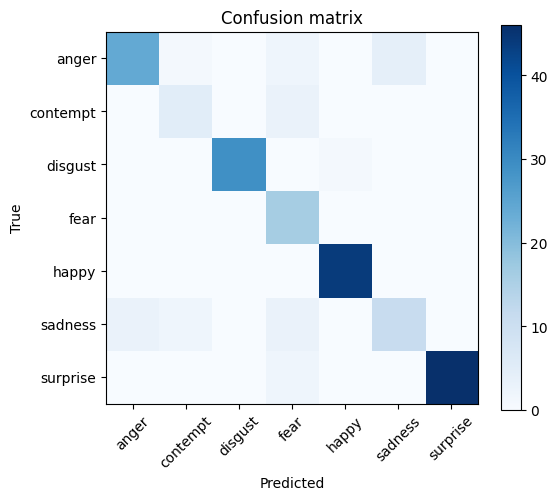

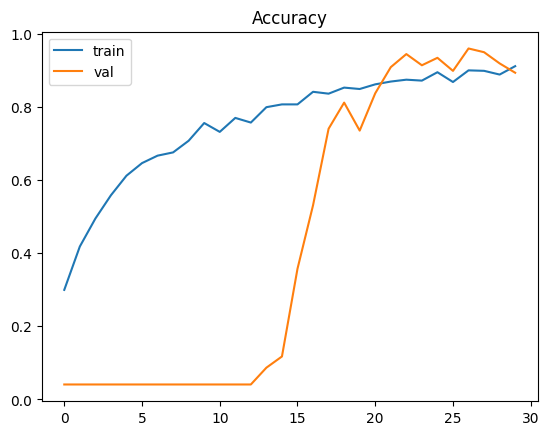

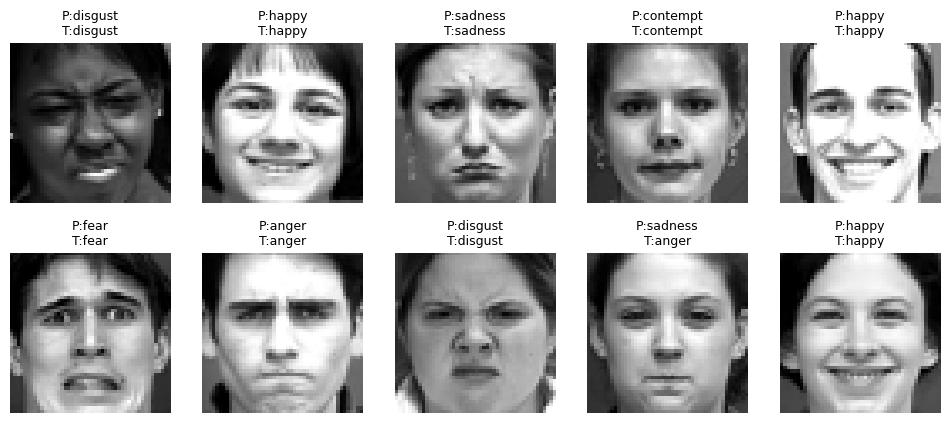

In [ ]:
loss, acc = model.evaluate(val_ds, verbose=0)
print(f"Validation accuracy: {acc*100:.2f}%")    # CK+ is easy (posed faces): usually 90%+

y_true, y_pred = [], []
for x, y in val_ds:
    y_true += list(y.numpy()); y_pred += list(np.argmax(model.predict(x, verbose=0), axis=1))
print(classification_report(y_true, y_pred, target_names=class_names, zero_division=0))

cm = confusion_matrix(y_true, y_pred)
plt.figure(figsize=(6, 5)); plt.imshow(cm, cmap='Blues'); plt.colorbar()
plt.xticks(range(len(class_names)), class_names, rotation=45); plt.yticks(range(len(class_names)), class_names)
plt.xlabel('Predicted'); plt.ylabel('True'); plt.title('Confusion matrix'); plt.show()

plt.plot(history.history['accuracy'], label='train'); plt.plot(history.history['val_accuracy'], label='val')
plt.legend(); plt.title('Accuracy'); plt.show()

imgs, labs = next(iter(val_ds))
pred = np.argmax(model.predict(imgs, verbose=0), axis=1)
plt.figure(figsize=(12, 5))
for i in range(10):
    plt.subplot(2, 5, i + 1); plt.imshow(imgs[i].numpy().squeeze(), cmap='gray')
    plt.title(f"P:{class_names[pred[i]]}\nT:{class_names[labs[i]]}", fontsize=9); plt.axis('off')
plt.show()

In [ ]:
Problem statement: "Facial Emotion Recognition using CNN: build a convolutional neural network (CNN) model to detect emotions from facial images (happy, sad, angry, etc.). Dataset: CK+."

(A small correction on Problem 5: the exact statement there was "Build a CNN model to detect emotions from facial images (happy, sad, angry, etc.). Dataset: FER-2013". The explanation I gave was for that task, so nothing else changes.)

1. What is the problem?

It is the same task as Problem 5: look at a face photo and say which emotion it shows. Only the dataset is different.

2. What is the CK+ dataset, and how is it different from FER-2013?

CK+ (Extended Cohn-Kanade) was recorded in a lab. Actors pose each emotion, going from a neutral face to the full expression. The labels are carefully verified. The Kaggle version we use is shawon10/ckplus: about 980 small (48×48) grayscale face images, in one folder per emotion (anger, contempt, disgust, fear, happy, sadness, surprise).

	FER-2013 (Problem 5)				CK+ (Problem 6)
Images	About 35,000					About 980 (only ~327 are unique; the Kaggle version repeats them 3 times)
Source	Photos from the internet ("in the wild")	Lab-recorded, posed faces
Quality	Noisy, blurry, some wrong labels		Clean, frontal, reliable labels
Typical accuracy	55–62%				90%+
Main challenge	Noisy and imbalanced data		Very small dataset, so it can overfit
3. What is the solution?

The CNN is almost the same as in Problem 5: three blocks of Conv + BatchNorm + MaxPool, then Flatten, Dense(128), Dropout(0.5), and a softmax output. Because the dataset is tiny, there are two changes:

More data augmentation: RandomFlip, RandomRotation(0.05) and RandomZoom(0.1). This creates slightly different versions of the same faces each epoch, so the model doesn't just memorise ~980
 images.
More epochs (30): a small dataset needs more passes to learn.
###########CODE########
tep 1: Download and find the folders

python
path = kagglehub.dataset_download('shawon10/ckplus')
data_dir = find_class_root(path)
print("Class folders:", sorted(os.listdir(data_dir)))

find_class_root is a small helper that walks the downloaded files and finds the folder that has one sub-folder per emotion. Check that the printed class names are the emotions.

Step 2: Load images and split

python
train_ds = keras.utils.image_dataset_from_directory(data_dir, color_mode='grayscale', image_size=(48,48),
              batch_size=32, validation_split=0.2, subset='training', seed=42)
val_ds = ... validation_split=0.2, subset='validation', seed=42

There is no ready-made test folder, so 80% of the images are for training and 20% for validation/testing. The same seed keeps the two parts separate.

Step 3: Build the model (same as Problem 5, plus RandomRotation and RandomZoom layers). The last layer has as many neurons as there are emotion folders (len(class_names)).

Step 4: Train

python
model.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])
history = model.fit(train_ds, validation_data=val_ds, epochs=30)

Step 5: Evaluate: validation accuracy, a classification report, a confusion matrix and an accuracy graph.

Step 6: Predict: shows 10 faces with predicted (P:) and true (T:) emotion.

5. The output you will see
Class folders: [...], the list of emotions (about 7).
About Found 981 files, split into about 785 training and 196 validation files.
A grid of sample faces.
Training for 30 epochs. Accuracy climbs fast, and the log may reach 95%+ on validation.
Validation accuracy of about 90–99%. I haven't run it on the real dataset, so go by your own number.
A classification report and a confusion matrix, mostly along the diagonal.
10 predicted faces, almost all correct.
6. The important point: why is accuracy so high? (the examiner may probe)
The faces are posed and clean: frontal, same lighting, exaggerated expressions.
The labels are verified and reliable.
Data leakage: CK+ has many near-identical frames of the same person. With a random 80/20 split, a very similar copy of a validation image can be in the training set, so the accuracy looks higher than real-world performance. A fair way is to split by person (subject-wise).

##############BLOCK##################
          START
            |
            v
        Load CK+ Dataset
            |
            v
      Preprocess Images
       (48 × 48 Gray)
            |
            v
       Split Dataset
      Train / Validation
            |
            v
      Data Augmentation
      Flip / Rotate / Zoom
            |
            v
        Build CNN Model
            |
            v
       Convolution + ReLU
            |
            v
         Batch Norm
            |
            v
         Max Pooling
            |
            v
       Repeat CNN Blocks
            |
            v
          Flatten
            |
            v
       Dense + Dropout
            |
            v
       Softmax (7 Classes)
            |
            v
        Train the Model
            |
            v
       Evaluate Accuracy
            |
            v
      Predict Emotions
            |
            v
           STOP



#################QUE
What is CK+? The Extended Cohn-Kanade dataset: lab-recorded sequences of subjects going from a neutral face to a peak expression, with verified emotion labels.
Why is CK+ accuracy higher than FER-2013? Clean, posed, frontal faces with reliable labels, while FER-2013 is noisy and "in the wild".
Why use data augmentation here? There are only about 980 images (about 327 unique), so augmentation gives variety and reduces overfitting.
What can go wrong with a random split here? Near-duplicate frames of one person land in both sets (data leakage), which inflates accuracy.
What is overfitting, and how is it reduced? The model memorises the training data. Dropout, augmentation and BatchNorm reduce it.
How could you improve results on a tiny dataset? Transfer learning with a pre-trained model such as MobileNet or VGG, more augmentation, or cross-validation.
How is this CNN different from Problem 1? Three conv blocks with BatchNorm, 48×48 grayscale input, 7 output classes, and augmentation layers.